## Long-Short Term Memory and Gated Recurrent Unit 

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import reuters
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    SimpleRNN,
    Dense,
    Embedding,
    Masking,
    LSTM,
    GRU,
    Conv1D,
    Dropout,
)
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences, TimeseriesGenerator

sns.set_context('notebook')
sns.set_style('white')
np.random.seed(2024)

## Gated RNN

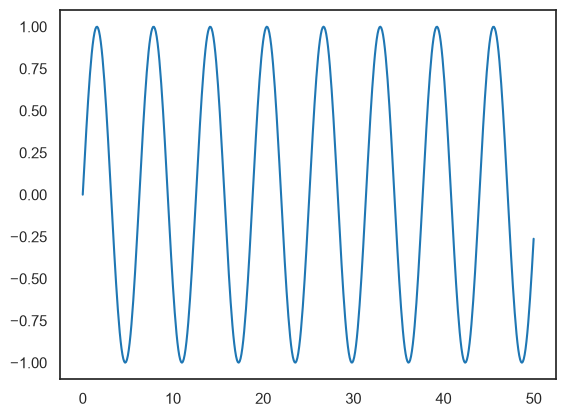

In [43]:
x = np.linspace(0, 50, 501)
y = np.sin(x)

df = pd.DataFrame(data=y, index=x, columns=['Sine'])

# percentage of data used for testing
test_percent = 0.1
# number of features
n_features = 1
# sequence length
length = 50
# batch size 
batch_size = 1

plt.plot(x, y)

In [44]:
# create the training and test set
test_point = np.round(len(df) * test_percent)
test_ind = int(len(df) - test_point)

train = df.iloc[:test_ind]
test = df.iloc[test_ind:]

scaler = MinMaxScaler()

scaled_train = scaler.fit_transform(train)
sclaed_test = scaler.transform(test)

# generate Time Series data
generator = TimeseriesGenerator(scaled_train, scaled_train, length=length, batch_size=batch_size)
len(generator)

401

In [45]:
# create an LSTM model with 50 units and input shaped defined by
# sequence length and n_feats

model = Sequential([
    LSTM(50, input_shape=(length, n_features)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(generator, epochs=6)
model.summary()

c:\Users\LEI\Documents\deep-learning-ibm\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/6
401/401 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0134
Epoch 2/6
401/401 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 2.5763e-04
Epoch 3/6
401/401 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 1.4520e-04
Epoch 4/6
401/401 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 2.9087e-04
Epoch 5/6
401/401 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 4.5054e-05
Epoch 6/6
401/401 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 8.4598e-05


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

In [46]:
forecast = []

first_eval_batch = scaled_train[-length:]
current_batch = first_eval_batch.reshape((1, length, n_features))

for x in range(25):
    current_prediction = model.predict(current_batch)[0]
    forecast.append(current_prediction)
    current_batch = np.append(current_batch[:, 1:, :], [[current_prediction]], axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 646ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


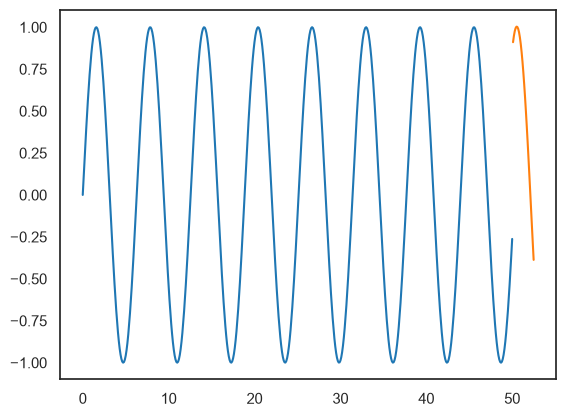

In [47]:
# invert the min-max scaling on the predictions
forecast = scaler.inverse_transform(forecast)
forecast_idx = np.arange(50.1, 52.6, step=0.1)

plt.plot(df.index, df['Sine'])
plt.plot(forecast_idx, forecast)

## Exercise: GRU - Reuters Classification

In [48]:
max_words = 10000
maxlen = 1000
test_split = 0.3

(xtrain, ytrain), (xtest, ytest) = reuters.load_data(num_words=max_words, test_split=test_split)
print(xtrain.shape, 'Train Sequences')
print(xtest.shape, 'Test Sequences\n')

# data preprocessing
xtrain = pad_sequences(xtrain, maxlen=maxlen)
xtest = pad_sequences(xtest, maxlen=maxlen)

ytrain = to_categorical(ytrain, 46)
ytest = to_categorical(ytest, 46)

print(xtrain.shape, 'Train Shape')
print(xtest.shape, 'Test Shape')

(7859,) Train Sequences
(3369,) Test Sequences

(7859, 1000) Train Shape
(3369, 1000) Test Shape


In [49]:
model = Sequential()
model.add(Embedding(input_dim = max_words, output_dim=300, input_length=1000))
model.add(GRU(128, dropout=0.2))
model.add(Dense(46, activation='softmax'))

model.summary()

c:\Users\LEI\Documents\deep-learning-ibm\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:119: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam', metrics=['accuracy']
)

model.fit(xtrain, ytrain, batch_size=256, epochs=10, validation_split=0.2)

Epoch 1/10
 4/25 ━━━━━━━━━━━━━━━━━━━━ 1:56 6s/step - accuracy: 0.2529 - loss: 3.7259